# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Khaylia Puspita Anjani
- **Email:** khaylianjani@gmail.com
- **ID Dicoding:** Khayp

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren jumlah pesanan dan total revenue (harga produk) per bulan pada periode Januari 2017 - Agustus 2018, serta 5 kategori produk mana yang menyumbang revenue terbesar, sehingga tim bisnis dapat memprioritaskan stok dan promosi?
- **Pertanyaan 2:** Berapa persentase pesanan yang terlambat (tanggal diterima pelanggan melewati estimasi) di setiap negara bagian pelanggan pada periode Januari 2017 - Agustus 2018, dan seberapa besar keterlambatan menurunkan rata-rata review score, sehingga tim logistik dapat menentukan wilayah prioritas perbaikan pengiriman?

| Elemen SMART | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Tren pesanan/revenue bulanan + kategori teratas | Keterlambatan per negara bagian + dampak ke review |
| Measurable | Jumlah pesanan, total revenue, kontribusi (%) kategori | % pesanan terlambat, selisih rata-rata review score |
| Action-Oriented | Prioritas stok & promosi | Prioritas perbaikan logistik wilayah |
| Relevant | Pertumbuhan penjualan marketplace | Kepuasan pelanggan & retensi |
| Time-bound | Jan 2017 - Agu 2018 | Jan 2017 - Agu 2018 |

*Catatan periode:* data tahun 2016 dan September-Oktober 2018 sangat sedikit (puluhan sampai ratusan pesanan), sehingga dikeluarkan agar tren tidak bias.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## Data Wrangling

### Gathering Data

#### Load seluruh tabel dataset

In [2]:
path = "data/"
customers = pd.read_csv(path + "customers_dataset.csv")
geolocation = pd.read_csv(path + "geolocation_dataset.csv")
order_items = pd.read_csv(path + "order_items_dataset.csv")
order_payments = pd.read_csv(path + "order_payments_dataset.csv")
order_reviews = pd.read_csv(path + "order_reviews_dataset.csv")
orders = pd.read_csv(path + "orders_dataset.csv")
products = pd.read_csv(path + "products_dataset.csv")
sellers = pd.read_csv(path + "sellers_dataset.csv")
translation = pd.read_csv(path + "product_category_name_translation.csv")

tables = {"customers": customers, "geolocation": geolocation, "order_items": order_items,
          "order_payments": order_payments, "order_reviews": order_reviews, "orders": orders,
          "products": products, "sellers": sellers, "translation": translation}
pd.DataFrame({n: d.shape for n, d in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
customers,99441,5
geolocation,1000163,5
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
orders,99441,8
products,32951,9
sellers,3095,4
translation,71,2


In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Dataset terdiri dari 9 tabel relasional; tabel `orders` menjadi pusat yang dihubungkan ke `customers`, `order_items`, `order_reviews`, dan `products` lewat kunci `order_id`, `customer_id`, dan `product_id`.
- `geolocation` adalah tabel terbesar (sekitar 1 juta baris) sehingga perlu diringkas per kode pos sebelum dipakai untuk analisis geospasial.

### Assessing Data

#### Memeriksa missing value dan duplikasi di semua tabel

In [4]:
summary = []
for n, d in tables.items():
    summary.append({"tabel": n, "baris": len(d), "total_missing": int(d.isna().sum().sum()),
                    "baris_duplikat": int(d.duplicated().sum())})
pd.DataFrame(summary)

,tabel,baris,total_missing,baris_duplikat
0,customers,99441,0,0
1,geolocation,1000163,0,261831
2,order_items,112650,0,0
3,order_payments,103886,0,0
4,order_reviews,99224,145903,0
5,orders,99441,4908,0
6,products,32951,2448,0
7,sellers,3095,0,0
8,translation,71,0,0


In [5]:
for n in ["orders", "order_reviews", "products"]:
    miss = tables[n].isna().sum()
    print(f"--- {n}"); print(miss[miss > 0], "\n")

--- orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

--- order_reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64 

--- products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 



#### Memeriksa masalah spesifik (invalid/inconsistent/inaccurate value dan outlier)

In [6]:
# 1. Distribusi status pesanan & rentang waktu
print(orders["order_status"].value_counts(), "\n")
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
print(orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size().loc[lambda s: (s.index < "2017-01") | (s.index > "2018-08")])

# 2. Pesanan berstatus delivered tetapi tanggal diterima kosong; pesanan canceled yang punya tanggal diterima
deliv = orders[orders["order_status"] == "delivered"]
print("\ndelivered tanpa tanggal diterima:", deliv["order_delivered_customer_date"].isna().sum())
print("non-delivered tetapi punya tanggal diterima:",
      orders[(orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()].shape[0])

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2018-09     16
2018-10      4
Freq: M, dtype: int64

delivered tanpa tanggal diterima: 8
non-delivered tetapi punya tanggal diterima: 6


In [7]:
# 3. Review ganda pada satu order
print("order dengan lebih dari 1 review:", order_reviews["order_id"].duplicated().sum())

# 4. Kategori produk kosong dan kategori tanpa terjemahan
print("kategori produk kosong:", products["product_category_name"].isna().sum())
print("kategori tanpa terjemahan:", set(products["product_category_name"].dropna()) - set(translation["product_category_name"]))

# 5. Geolocation: duplikat dan koordinat di luar wilayah Brasil
print("duplikat geolocation:", geolocation.duplicated().sum())
out = geolocation[(geolocation["geolocation_lat"] > 5.3) | (geolocation["geolocation_lat"] < -34) |
                  (geolocation["geolocation_lng"] < -74) | (geolocation["geolocation_lng"] > -34)]
print("koordinat di luar Brasil:", len(out))

# 6. Outlier harga & ongkir
order_items[["price", "freight_value"]].describe()

order dengan lebih dari 1 review: 551
kategori produk kosong: 610
kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


duplikat geolocation: 261831
koordinat di luar Brasil: 42


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


**Steps to Take:**
- **Missing value (`orders`)**: pesanan `delivered` tanpa tanggal diterima dihapus karena lama pengiriman tidak bisa dihitung. Analisis pengiriman hanya memakai pesanan berstatus `delivered`.
- **Invalid value (periode)**: pesanan tahun 2016 dan September-Oktober 2018 hanya segelintir, sehingga dibatasi ke Januari 2017 - Agustus 2018.
- **Missing & inconsistent value (`products`)**: kategori kosong diisi `unknown`; 2 kategori tanpa terjemahan diterjemahkan manual; nama kategori diseragamkan ke bahasa Inggris.
- **Duplicate data (`order_reviews`)**: order dengan lebih dari satu review dipertahankan satu review terbaru saja agar `review_score` tidak menggandakan order.
- **Duplicate & inaccurate value (`geolocation`)**: hapus duplikat, buang koordinat di luar Brasil, lalu ringkas per kode pos (rata-rata lat/lng).
- **Outlier (`price`, `freight_value`)**: nilai ekstrem (harga hingga 6.735) dicek sebagai produk bernilai tinggi yang wajar, sehingga dipertahankan dan dibaca dengan median/kontribusi agar tidak menyesatkan.

**Insight:**
- Missing value terbesar ada di `orders` (tanggal persetujuan, pengiriman, dan penerimaan) dan `products` (610 produk tanpa kategori); kolom komentar di `order_reviews` memang opsional sehingga tidak dianggap masalah.
- Duplikasi paling besar ada di `geolocation` (261.831 baris atau sekitar 26%), dan 551 order memiliki lebih dari satu review.
- Ditemukan 8 pesanan `delivered` tanpa tanggal diterima, 6 pesanan `canceled` yang justru punya tanggal diterima (data tidak konsisten), 2 kategori tanpa terjemahan, dan 42 koordinat di luar Brasil.
- Data 2016 dan September-Oktober 2018 hanya berisi sangat sedikit pesanan sehingga tidak representatif untuk tren.

### Cleaning Data

#### Fixing missing value, invalid periode, dan status pesanan

In [8]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

n0 = len(orders)
orders_clean = orders[(orders["order_purchase_timestamp"] >= "2017-01-01") &
                      (orders["order_purchase_timestamp"] < "2018-09-01")].copy()
print("setelah filter periode:", len(orders_clean), "dari", n0)

delivered = orders_clean[orders_clean["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"]).copy()
print("pesanan delivered valid:", len(delivered))

setelah filter periode: 99092 dari 99441


pesanan delivered valid: 96203


#### Fixing inconsistent/missing value pada kategori produk

In [9]:
products["product_category_name"] = products["product_category_name"].fillna("unknown")
cat_map = translation.set_index("product_category_name")["product_category_name_english"].to_dict()
cat_map.update({"pc_gamer": "pc_gamer",
                "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_preparers",
                "unknown": "unknown"})
products["category"] = products["product_category_name"].map(cat_map)
print("kategori belum terpetakan:", products["category"].isna().sum())

kategori belum terpetakan: 0


#### Fixing duplicate data pada review

In [10]:
order_reviews = (order_reviews.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last"))
print("order unik di review:", order_reviews["order_id"].nunique(), "| baris:", len(order_reviews))

order unik di review: 98673 | baris: 98673


#### Fixing duplicate & inaccurate value pada geolocation

In [11]:
geo = geolocation.drop_duplicates().copy()
geo = geo[(geo["geolocation_lat"].between(-34, 5.3)) & (geo["geolocation_lng"].between(-74, -34))]
geo_zip = (geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
           .mean().reset_index())
print(len(geolocation), "->", len(geo_zip), "kode pos unik")

1000163 -> 19010 kode pos unik


#### Menggabungkan tabel menjadi dataset analisis

In [12]:
df = (order_items
      .merge(delivered[["order_id", "customer_id", "order_purchase_timestamp",
                        "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id")
      .merge(customers[["customer_id", "customer_unique_id", "customer_state", "customer_zip_code_prefix"]], on="customer_id")
      .merge(products[["product_id", "category"]], on="product_id", how="left")
      .merge(order_reviews[["order_id", "review_score"]], on="order_id", how="left"))

df["order_month"] = df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
df["is_late"] = (df["order_delivered_customer_date"].dt.normalize() > df["order_estimated_delivery_date"]).astype(int)

print(df.shape)
print("missing review_score:", df["review_score"].isna().sum())
df.head()

(109872, 19)
missing review_score: 823


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,customer_zip_code_prefix,category,review_score,order_month,delivery_days,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,RJ,28013,cool_stuff,5.0,2017-09-01,7.614421,0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,SP,15775,pet_shop,4.0,2017-04-01,16.216181,0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,MG,35661,furniture_decor,5.0,2018-01-01,7.948437,0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,SP,12952,perfumery,4.0,2018-08-01,6.147269,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,SP,13226,garden_tools,5.0,2017-02-01,25.114352,0


In [13]:
# Tabel level order (satu baris per order) untuk analisis pengiriman & review
orders_df = (df.groupby("order_id")
             .agg(order_month=("order_month", "first"), customer_unique_id=("customer_unique_id", "first"),
                  customer_state=("customer_state", "first"), delivery_days=("delivery_days", "first"),
                  is_late=("is_late", "first"), review_score=("review_score", "first"),
                  revenue=("price", "sum"))
             .reset_index())
print(orders_df.shape)
orders_df.describe().round(2)

(96203, 8)


,order_month,delivery_days,is_late,review_score,revenue
count,96203,96203.00,96203.00,95560.00,96203.00
mean,2017-12-19 01:06:57.205284,12.54,0.07,4.16,137.00
min,2017-01-01 00:00:00,0.53,0.00,1.00,0.85
25%,2017-09-01 00:00:00,6.76,0.00,4.00,45.90
50%,2018-01-01 00:00:00,10.21,0.00,5.00,86.50
75%,2018-05-01 00:00:00,15.68,0.00,5.00,149.90
max,2018-08-01 00:00:00,209.63,1.00,5.00,13440.00
std,NaN,9.53,0.25,1.28,209.12


**Insight:**
- Filter periode Jan 2017 - Agu 2018 menyisakan 99.092 dari 99.441 pesanan; dari situ 96.203 pesanan `delivered` valid dipakai untuk analisis pengiriman dan revenue.
- Dataset gabungan berisi 109.872 baris item. Sebanyak 823 baris (0,7%) tidak punya review dan dibiarkan kosong agar tidak mengubah rata-rata review.
- Keterlambatan dihitung jika tanggal diterima melewati tanggal estimasi. Rata-rata lama pengiriman 12,5 hari (median 10,2 hari) dengan nilai maksimum 209 hari, sehingga median dan binning dipakai untuk membaca data yang miring ke kanan.

## Exploratory Data Analysis (EDA)

### Explore tren pesanan dan revenue bulanan

In [14]:
monthly = (df.groupby("order_month")
           .agg(orders=("order_id", "nunique"), revenue=("price", "sum"))
           .reset_index())
monthly["aov"] = monthly["revenue"] / monthly["orders"]
monthly["revenue_mom_%"] = monthly["revenue"].pct_change() * 100
monthly.round({"revenue": 1, "aov": 1, "revenue_mom_%": 1})

,order_month,orders,revenue,aov,revenue_mom_%
0,2017-01-01,750,111798.4,149.1,NaN
1,2017-02-01,1653,234223.4,141.7,109.5
2,2017-03-01,2546,359198.8,141.1,53.4
3,2017-04-01,2303,340669.7,147.9,-5.2
4,2017-05-01,3545,489159.2,138.0,43.6
5,2017-06-01,3135,421923.4,134.6,-13.7
6,2017-07-01,3872,481604.5,124.4,14.1
7,2017-08-01,4193,554699.7,132.3,15.2
8,2017-09-01,4150,607399.7,146.4,9.5
9,2017-10-01,4478,648247.6,144.8,6.7


### Explore kategori produk

In [15]:
cat_rev = (df.groupby("category")
           .agg(revenue=("price", "sum"), items=("order_id", "count"), avg_review=("review_score", "mean"))
           .sort_values("revenue", ascending=False))
cat_rev["share_%"] = cat_rev["revenue"] / cat_rev["revenue"].sum() * 100
cat_rev["cum_share_%"] = cat_rev["share_%"].cumsum()
cat_rev.head(10).round(2)

,revenue,items,avg_review,share_%,cum_share_%
category,,,,,
health_beauty,1229557.50,9422,4.19,9.33,9.33
watches_gifts,1163187.91,5853,4.07,8.83,18.15
bed_bath_table,1022955.77,10945,3.92,7.76,25.92
sports_leisure,952661.40,8413,4.16,7.23,33.14
computers_accessories,887944.60,7631,3.99,6.74,39.88
furniture_decor,706237.17,8095,3.96,5.36,45.24
housewares,614341.62,6783,4.11,4.66,49.90
cool_stuff,609158.00,3711,4.20,4.62,54.52
auto,577721.09,4131,4.12,4.38,58.91


In [16]:
cat_rev.tail(5).round(2)

,revenue,items,avg_review,share_%,cum_share_%
category,,,,,
flowers,1110.04,33,4.42,0.01,99.98
home_comfort_2,760.27,30,3.63,0.01,99.99
cds_dvds_musicals,730.00,14,4.64,0.01,99.99
fashion_childrens_clothes,519.95,7,5.00,0.00,100.00
security_and_services,283.29,2,2.50,0.00,100.00


### Explore keterlambatan pengiriman per negara bagian

In [17]:
print(orders_df["delivery_days"].describe().round(1))
print("\n% order terlambat nasional:", round(orders_df["is_late"].mean() * 100, 2))

state = (orders_df.groupby("customer_state")
         .agg(orders=("order_id", "count"), late_pct=("is_late", lambda s: s.mean() * 100),
              avg_delivery_days=("delivery_days", "mean"), avg_review=("review_score", "mean"))
         .sort_values("late_pct", ascending=False))
state.round(2)

count    96203.0
mean        12.5
std          9.5
min          0.5
25%          6.8
50%         10.2
75%         15.7
max        209.6
Name: delivery_days, dtype: float64

% order terlambat nasional: 6.79


,orders,late_pct,avg_delivery_days,avg_review
customer_state,,,,
AL,396,21.46,24.52,3.85
MA,713,17.53,21.54,3.83
SE,332,15.36,21.44,3.90
PI,475,13.89,19.44,3.99
CE,1273,13.83,21.24,3.94
RR,40,12.50,29.91,3.90
BA,3253,12.17,19.33,3.93
RJ,12310,12.14,15.30,3.97
PA,942,11.25,23.76,3.91


In [18]:
review_by_late = orders_df.groupby("is_late")["review_score"].agg(["mean", "count"])
review_by_late.index = ["Tepat waktu", "Terlambat"]
review_by_late.round(2)

,mean,count
Tepat waktu,4.29,89182
Terlambat,2.27,6378


**Insight:**
- Jumlah pesanan bulanan naik dari 750 (Jan 2017) menjadi 7.288 (Nov 2017), lalu bertahan di kisaran 6.000-7.000 sepanjang 2018. Nov 2017 adalah puncak revenue (sekitar 988 ribu BRL, naik 52,4% dari Oktober), diikuti penurunan 26,5% di Desember.
- Nilai rata-rata per order (AOV) relatif stabil di 124-149 BRL, jadi pertumbuhan berasal dari jumlah pesanan, bukan kenaikan nilai keranjang.
- Lima kategori teratas (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) menyumbang 39,9% revenue; 10 teratas menyumbang 62,5%.
- Persentase pesanan terlambat nasional 6,79%, tetapi sangat timpang antarwilayah: AL 21,5%, MA 17,5%, SE 15,4% dibandingkan SP 4,5% dan PR 4,1%.
- Rata-rata review pesanan tepat waktu 4,29 versus 2,27 untuk pesanan terlambat.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren pesanan & revenue bulanan, dan kategori apa yang menyumbang revenue terbesar?

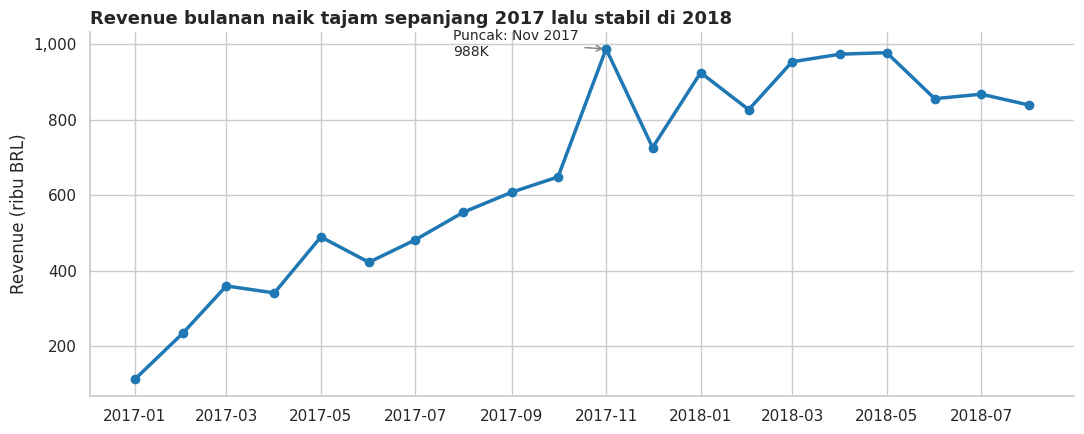

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly["order_month"], monthly["revenue"] / 1e3, color="#1f77b4", lw=2.5, marker="o")
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.annotate(f"Puncak: {peak['order_month']:%b %Y}\n{peak['revenue']/1e3:,.0f}K",
            xy=(peak["order_month"], peak["revenue"] / 1e3), xytext=(-110, -5),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="gray"), fontsize=10)
ax.set_title("Revenue bulanan naik tajam sepanjang 2017 lalu stabil di 2018", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("Revenue (ribu BRL)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
sns.despine(); plt.tight_layout(); plt.show()

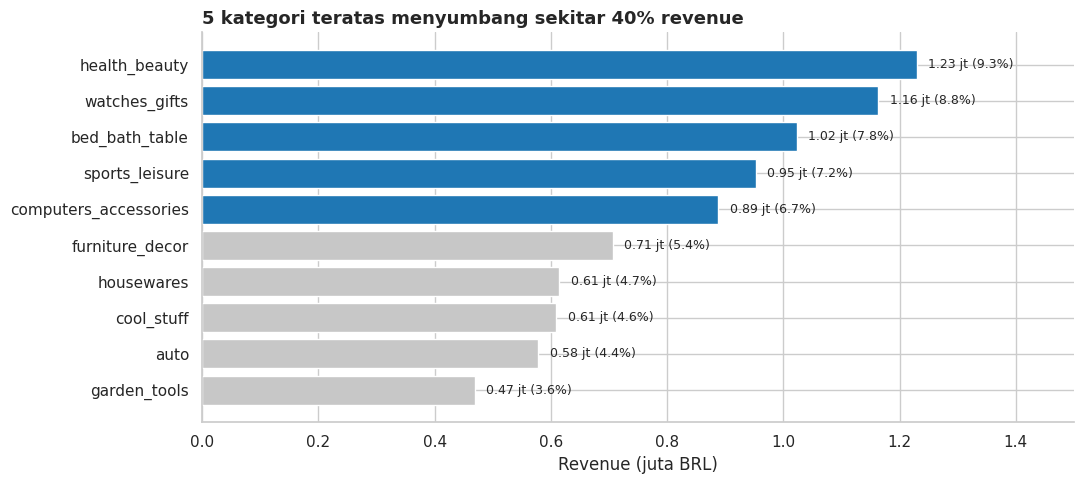

In [20]:
top = cat_rev.head(10).reset_index()
colors = ["#1f77b4"] * 5 + ["#c7c7c7"] * 5
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top["category"][::-1], top["revenue"][::-1] / 1e6, color=colors[::-1])
for i, (r, s) in enumerate(zip(top["revenue"][::-1], top["share_%"][::-1])):
    ax.text(r / 1e6 + 0.02, i, f"{r/1e6:.2f} jt ({s:.1f}%)", va="center", fontsize=9)
ax.set_title("5 kategori teratas menyumbang sekitar {:.0f}% revenue".format(top['share_%'][:5].sum()),
             loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Revenue (juta BRL)"); ax.set_ylabel("")
ax.set_xlim(0, top["revenue"].max() / 1e6 * 1.22)
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Revenue bulanan tumbuh sekitar 9 kali lipat dari Jan ke Nov 2017 (112 ribu ke 988 ribu BRL), lalu mendatar di 830-980 ribu BRL pada 2018, dengan sedikit penurunan sejak Juni 2018.
- Revenue sangat terkonsentrasi: health_beauty (9,3%), watches_gifts (8,8%), dan bed_bath_table (7,8%) menjadi tiga teratas, sementara kategori terbawah seperti security_and_services hanya menghasilkan sekitar 283 BRL.

### Pertanyaan 2: Berapa persen pesanan terlambat per negara bagian dan dampaknya ke review score?

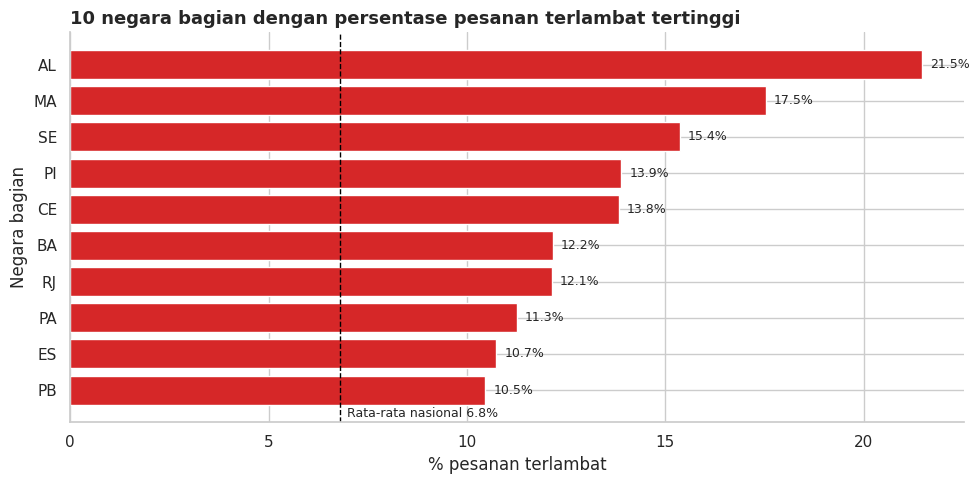

In [21]:
s = state[state["orders"] >= 200].sort_values("late_pct", ascending=False).head(10).iloc[::-1]
nat = orders_df["is_late"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(s.index, s["late_pct"], color=["#d62728" if v > nat else "#c7c7c7" for v in s["late_pct"]])
ax.axvline(nat, color="black", ls="--", lw=1)
ax.text(nat + 0.2, -0.75, f"Rata-rata nasional {nat:.1f}%", fontsize=9)
for i, v in enumerate(s["late_pct"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("10 negara bagian dengan persentase pesanan terlambat tertinggi", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("% pesanan terlambat"); ax.set_ylabel("Negara bagian")
sns.despine(); plt.tight_layout(); plt.show()

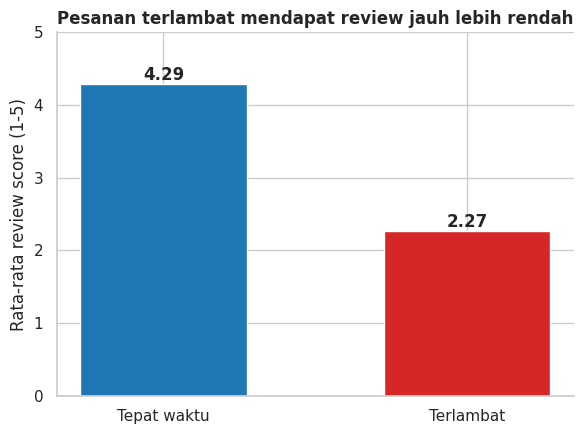

In [22]:
fig, ax = plt.subplots(figsize=(6, 4.5))
vals = review_by_late["mean"]
ax.bar(vals.index, vals.values, color=["#1f77b4", "#d62728"], width=0.55)
for i, v in enumerate(vals.values):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 5)
ax.set_title("Pesanan terlambat mendapat review jauh lebih rendah", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("Rata-rata review score (1-5)")
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Delapan dari sepuluh wilayah dengan tingkat keterlambatan tertinggi berada di Timur Laut dan Utara (AL, MA, SE, PI, CE, BA, PA, PB). RJ juga di atas rata-rata nasional (12,1%) dengan volume besar (12.310 pesanan).
- Keterlambatan menurunkan rata-rata review sebesar 2,02 poin (4,29 menjadi 2,27), jadi dampaknya ke kepuasan pelanggan sangat besar.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan (tanpa machine learning) diterapkan:
1. **RFM Analysis** - mengelompokkan pelanggan (`customer_unique_id`) berdasarkan Recency (hari sejak pembelian terakhir), Frequency (jumlah order), dan Monetary (total belanja) untuk menentukan strategi retensi.
2. **Geospatial Analysis** - memetakan jumlah pesanan dan persentase keterlambatan per negara bagian berdasarkan koordinat kode pos pelanggan, untuk melihat pola wilayah.
3. **Clustering (Manual Grouping & Binning)** - segmentasi pelanggan berdasarkan aturan bisnis skor RFM, dan pengelompokan lama pengiriman ke dalam interval (bin) untuk melihat hubungannya dengan kepuasan.

### RFM Analysis

In [23]:
snapshot = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = (df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"),
            monetary=("price", "sum")).reset_index())
rfm["recency"] = (snapshot - rfm["last_purchase"]).dt.days

# Skor 1-5 berbasis kuantil (recency dibalik: makin baru makin tinggi)
rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Frequency ~97% bernilai 1, sehingga dikelompokkan manual (bukan kuantil)
print(rfm["frequency"].value_counts(normalize=True).head(4).round(3))

conds = [(rfm["frequency"] >= 2) & (rfm["m_score"] >= 4),
         (rfm["frequency"] >= 2),
         (rfm["r_score"] >= 4) & (rfm["m_score"] >= 4),
         (rfm["r_score"] >= 4),
         (rfm["r_score"] <= 3) & (rfm["m_score"] >= 4)]
names = ["Repeat - High Value", "Repeat Customer", "New - High Value", "New Customer", "At Risk - High Value"]
rfm["segment"] = np.select(conds, names, default="Dormant")

seg = (rfm.groupby("segment").agg(customers=("customer_unique_id", "count"), avg_recency=("recency", "mean"),
                                   avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"),
                                   total_monetary=("monetary", "sum")).sort_values("customers", ascending=False))
seg["customer_%"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_%"] = seg["total_monetary"] / seg["total_monetary"].sum() * 100
seg.round(1)

frequency
1    0.970
2    0.028
3    0.002
4    0.000
Name: proportion, dtype: float64


,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_%,revenue_%
segment,,,,,,,
Dormant,33592,335.5,1.0,55.6,1868822.3,36.1,14.2
New Customer,21602,89.4,1.0,55.5,1199345.4,23.2,9.1
At Risk - High Value,20672,334.0,1.0,267.4,5528349.1,22.2,41.9
New - High Value,14441,91.4,1.0,267.1,3857906.2,15.5,29.3
Repeat - High Value,2125,215.5,2.1,318.3,676367.1,2.3,5.1
Repeat Customer,664,232.7,2.0,73.8,48987.9,0.7,0.4


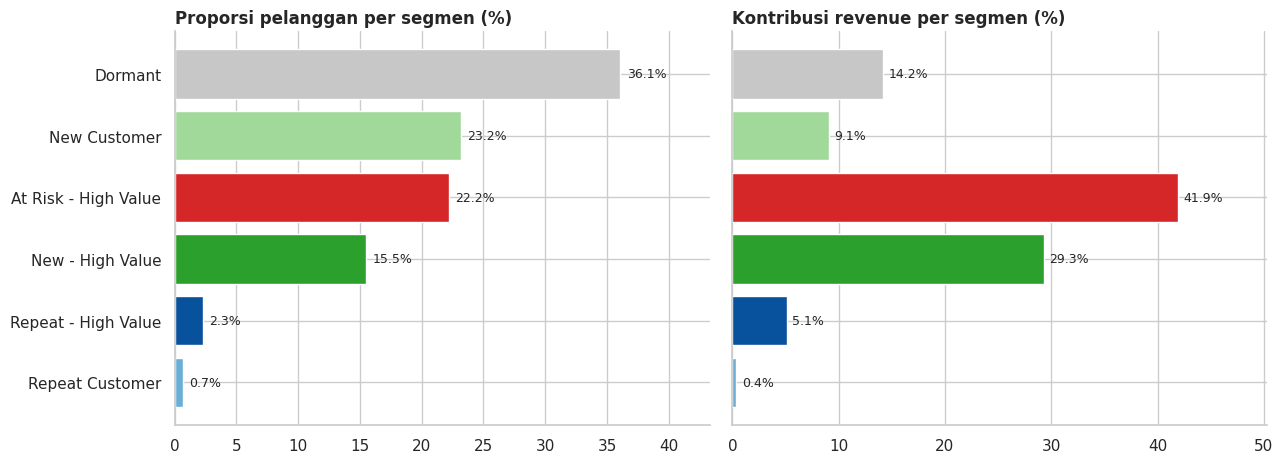

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order = seg.index.tolist()
pal = {s: c for s, c in zip(["Repeat - High Value", "Repeat Customer", "New - High Value", "New Customer",
                              "At Risk - High Value", "Dormant"],
                             ["#08519c", "#6baed6", "#2ca02c", "#a1d99b", "#d62728", "#c7c7c7"])}
axes[0].barh(order[::-1], seg["customer_%"][::-1], color=[pal[s] for s in order[::-1]])
axes[0].set_title("Proporsi pelanggan per segmen (%)", loc="left", fontweight="bold")
axes[1].barh(order[::-1], seg["revenue_%"][::-1], color=[pal[s] for s in order[::-1]])
axes[1].set_title("Kontribusi revenue per segmen (%)", loc="left", fontweight="bold")
for ax, col in zip(axes, ["customer_%", "revenue_%"]):
    for i, v in enumerate(seg[col][::-1]):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, seg[col].max() * 1.2)
axes[1].set_yticklabels([])
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Sekitar 97% pelanggan hanya membeli satu kali; segmen repeat (Repeat - High Value dan Repeat Customer) hanya 3,0% dari pelanggan dan 5,5% dari revenue.
- Segmen At Risk - High Value (22,2% pelanggan) menyumbang 41,9% revenue, dan New - High Value (15,5% pelanggan) menyumbang 29,3%. Pelanggan bernilai tinggi yang belum kembali adalah sumber risiko sekaligus peluang terbesar.
- Segmen Dormant berisi 36,1% pelanggan tetapi hanya 14,2% revenue, sehingga prioritas win-back rendah.

### Geospatial Analysis

In [25]:
cust_geo = (customers.merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="inner"))
state_geo = (cust_geo.groupby("customer_state")[["geolocation_lat", "geolocation_lng"]].mean()
             .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"}))
state_map = state.join(state_geo).dropna(subset=["lat"]).reset_index()
state_map.head()

,customer_state,orders,late_pct,avg_delivery_days,avg_review,lat,lng
0,AL,396,21.464646,24.522339,3.847328,-9.673097,-36.061796
1,MA,713,17.531557,21.535557,3.829337,-3.562138,-44.682132
2,SE,332,15.361446,21.438612,3.900302,-10.875183,-37.172582
3,PI,475,13.894737,19.440832,3.993617,-5.503758,-42.589286
4,CE,1273,13.825609,21.238458,3.940016,-4.319673,-38.956231


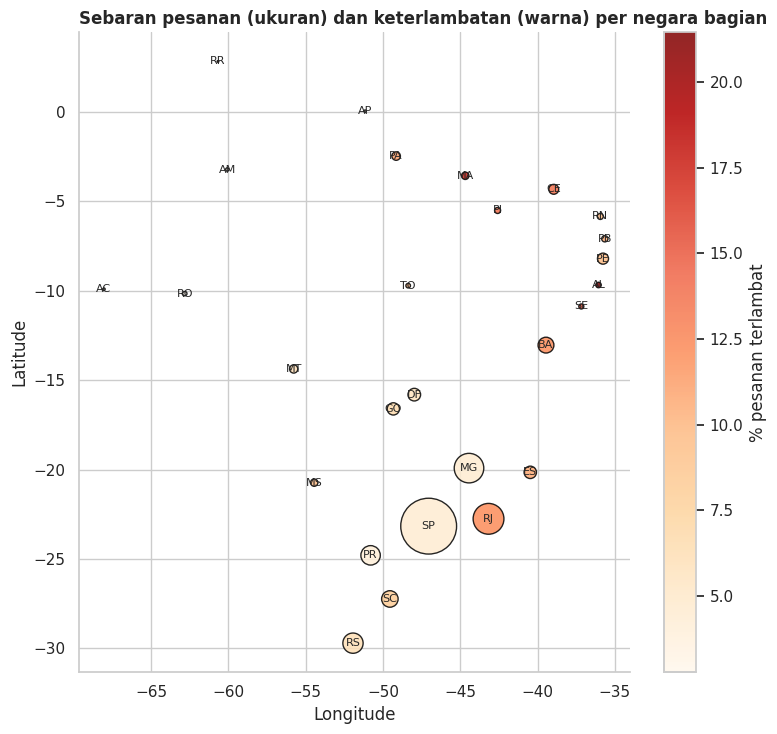

In [26]:
fig, ax = plt.subplots(figsize=(8, 7.5))
sc = ax.scatter(state_map["lng"], state_map["lat"], s=state_map["orders"] / 25,
                c=state_map["late_pct"], cmap="OrRd", edgecolor="black", alpha=0.85)
for _, r in state_map.iterrows():
    ax.text(r["lng"], r["lat"], r["customer_state"], ha="center", va="center", fontsize=8)
plt.colorbar(sc, label="% pesanan terlambat")
ax.set_title("Sebaran pesanan (ukuran) dan keterlambatan (warna) per negara bagian", loc="left", fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
sns.despine(); plt.tight_layout(); plt.show()

In [27]:
m = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles="OpenStreetMap")
for _, r in state_map.iterrows():
    folium.CircleMarker([r["lat"], r["lng"]], radius=max(4, r["orders"] ** 0.5 / 8),
                        color="#d62728" if r["late_pct"] > nat else "#1f77b4", fill=True, fill_opacity=0.7,
                        tooltip=f"{r['customer_state']}: {int(r['orders'])} pesanan, {r['late_pct']:.1f}% terlambat, "
                                f"review {r['avg_review']:.2f}").add_to(m)
m

**Insight:**
- Pesanan terkonsentrasi di Tenggara dan Selatan (SP saja sekitar 42% dari seluruh pesanan), sedangkan keterlambatan tertinggi berada di wilayah jauh dari pusat penjual seperti Timur Laut.
- Rata-rata lama pengiriman SP 8,7 hari, jauh lebih cepat dibanding AL 24,5 hari dan RR 29,9 hari. Jarak dan jaringan logistik diduga menjadi faktor, tetapi dataset ini tidak memuat data carrier sehingga penyebab pastinya belum bisa dipastikan.

### Clustering: Binning Lama Pengiriman

In [28]:
bins = [0, 7, 14, 21, np.inf]
labels = ["<= 7 hari", "8-14 hari", "15-21 hari", "> 21 hari"]
orders_df["delivery_bin"] = pd.cut(orders_df["delivery_days"], bins=bins, labels=labels)
bin_sum = (orders_df.groupby("delivery_bin", observed=True)
           .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"), late_pct=("is_late", lambda s: s.mean() * 100)))
bin_sum["orders_%"] = bin_sum["orders"] / bin_sum["orders"].sum() * 100
bin_sum.round(2)

,orders,avg_review,late_pct,orders_%
delivery_bin,,,,
<= 7 hari,26038,4.42,0.23,27.07
8-14 hari,40111,4.31,0.79,41.69
15-21 hari,17653,4.14,3.02,18.35
> 21 hari,12401,3.12,45.31,12.89


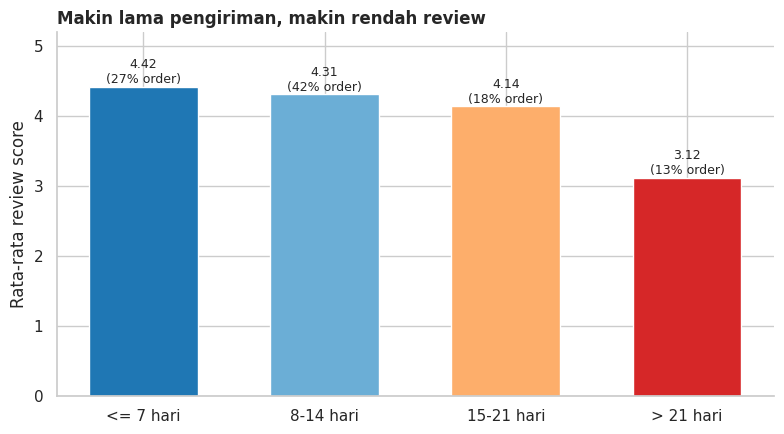

In [29]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(bin_sum.index.astype(str), bin_sum["avg_review"],
       color=["#1f77b4", "#6baed6", "#fdae6b", "#d62728"], width=0.6)
for i, (v, p) in enumerate(zip(bin_sum["avg_review"], bin_sum["orders_%"])):
    ax.text(i, v + 0.05, f"{v:.2f}\n({p:.0f}% order)", ha="center", fontsize=9)
ax.set_ylim(0, 5.2); ax.set_ylabel("Rata-rata review score")
ax.set_title("Makin lama pengiriman, makin rendah review", loc="left", fontweight="bold")
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Review turun konsisten seiring lama pengiriman: 4,42 (<= 7 hari), 4,31 (8-14 hari), 4,14 (15-21 hari), dan 3,12 (> 21 hari).
- Kelompok > 21 hari hanya 12,9% dari pesanan tetapi 45,3% di antaranya terlambat dari estimasi, sehingga kelompok ini paling perlu dipantau.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pesanan dan revenue tumbuh pesat sepanjang 2017 (puncak Nov 2017 sekitar 988 ribu BRL) lalu mendatar di 2018 pada kisaran 830-980 ribu BRL per bulan. Pertumbuhan didorong jumlah pesanan karena AOV stabil. Lima kategori teratas (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) menyumbang sekitar 40% revenue.
- **Conclusion pertanyaan 2:** Sebanyak 6,79% pesanan terlambat secara nasional, tetapi persentasenya mencapai 21,5% di AL, 17,5% di MA, dan 15,4% di SE, dengan wilayah Timur Laut mendominasi daftar teratas. Keterlambatan menurunkan rata-rata review dari 4,29 menjadi 2,27, dan review terendah terjadi pada pengiriman di atas 21 hari (3,12).

**Rekomendasi Action Item:**
- **Stok & promosi:** prioritaskan stok dan anggaran promosi untuk 5 kategori teratas, dan siapkan kapasitas stok serta logistik menjelang November karena lonjakan permintaan terbesar terjadi di bulan tersebut (kemungkinan terkait momen belanja akhir tahun seperti Black Friday; data ini tidak memuat penyebabnya secara langsung).
- **Logistik wilayah:** jadikan AL, MA, SE, PI, CE, dan BA prioritas perbaikan (carrier regional, gudang/stok lebih dekat, estimasi pengiriman yang lebih realistis), serta pantau RJ karena volumenya besar. Target awal: turunkan tingkat keterlambatan wilayah tersebut mendekati rata-rata nasional 6,8%.
- **Monitoring pengiriman:** pantau khusus pesanan yang melewati 14 hari dan tindak lanjuti proaktif (notifikasi/kompensasi) sebelum pelanggan memberi review rendah.
- **Retensi:** jalankan kampanye win-back (voucher/email) ke segmen At Risk - High Value dan program pembelian ulang untuk New - High Value, karena dua segmen ini membawa sekitar 71% revenue sementara pelanggan repeat baru 3%.

In [30]:
# Simpan data untuk dashboard
import os
os.makedirs("dashboard", exist_ok=True)
main = df[["order_id", "order_purchase_timestamp", "customer_unique_id", "customer_state", "category",
           "price", "freight_value", "review_score", "delivery_days", "is_late"]].copy()
main["delivery_days"] = main["delivery_days"].round(2)
main.to_csv("dashboard/main_data.csv", index=False)
state_geo.reset_index().round(4).to_csv("dashboard/state_geo.csv", index=False)
print(main.shape)

(109872, 10)
